In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4


In [ ]:
!pip install -q datasets

In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt

from datasets import load_dataset

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
ds = load_dataset("zacharielegault/Kermany2017-OCT")

print(ds)

README.md:   0%|          | 0.00/2.79k [00:00<?, ?B/s]

data/train-00000-of-00016.parquet: reconstructing file:   0%|          |  0.00B /  369MB            

data/train-00000-of-00016.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00016.parquet: reconstructing file:   0%|          |  0.00B /  473MB            

data/train-00001-of-00016.parquet: downloading bytes:           |  0.00B            

data/train-00002-of-00016.parquet: reconstructing file:   0%|          |  0.00B /  462MB            

... (28 outputs left out)

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/108309 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 108309
    })
    test: Dataset({
        features: ['image', 'label'],
        num_rows: 1000
    })
})


In [ ]:
train_data = ds["train"]
test_data = ds["test"]

label_names = train_data.features["label"].names

print("Training samples:", len(train_data))
print("Testing samples:", len(test_data))
print("Class labels:", label_names)

Training samples: 108309
Testing samples: 1000
Class labels: ['CNV', 'DME', 'DRUSEN', 'NORMAL']


In [ ]:
train_data = ds["train"]
test_data = ds["test"]

label_names = train_data.features["label"].names

split_data = train_data.train_test_split(
    test_size=0.2,
    seed=42,
    stratify_by_column="label"
)

actual_train_data = split_data["train"]
val_data = split_data["test"]

print("Training samples:", len(actual_train_data))
print("Validation samples:", len(val_data))
print("Testing samples:", len(test_data))
print("Labels:", label_names)

Training samples: 86647
Validation samples: 21662
Testing samples: 1000
Labels: ['CNV', 'DME', 'DRUSEN', 'NORMAL']


Image Transformation

In [ ]:
from torchvision import transforms

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5], std=[0.5])
])

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5], std=[0.5])
])

Apply transformations to the datasets

In [ ]:
train_dataset = actual_train_data.with_transform(
    lambda examples: {
        "pixel_values": [
            train_transform(image.convert("L"))
            for image in examples["image"]
        ],
        "label": examples["label"]
    }
)

val_dataset = val_data.with_transform(
    lambda examples: {
        "pixel_values": [
            eval_transform(image.convert("L"))
            for image in examples["image"]
        ],
        "label": examples["label"]
    }
)

test_dataset = test_data.with_transform(
    lambda examples: {
        "pixel_values": [
            eval_transform(image.convert("L"))
            for image in examples["image"]
        ],
        "label": examples["label"]
    }
)

Create DataLoaders

In [ ]:
from torch.utils.data import DataLoader

batch_size = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

In [ ]:
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

Training batches: 2708
Validation batches: 677
Testing batches: 32


In [ ]:
batch = next(iter(train_loader))

print("Batch keys:", batch.keys())

print("Image batch shape:", batch["pixel_values"].shape)

print("Label batch shape:", batch["label"].shape)

print("First 10 labels:", batch["label"][:10])

Batch keys: dict_keys(['pixel_values', 'label'])
Image batch shape: torch.Size([32, 1, 224, 224])
Label batch shape: torch.Size([32])
First 10 labels: tensor([3, 0, 0, 3, 3, 0, 3, 3, 3, 3])


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim

print("PyTorch version:", torch.__version__)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)

PyTorch version: 2.14.1+cu130
Using device: cuda


In [ ]:
class CustomCNN(nn.Module):

    def __init__(self):
        super(CustomCNN, self).__init__()

        self.features = nn.Sequential(

            # First convolution block
            nn.Conv2d(
                in_channels=1,
                out_channels=32,
                kernel_size=3,
                padding=1
            ),

            nn.ReLU(),

            nn.MaxPool2d(kernel_size=2)
        )

Add more convolution layers

In [ ]:
class CustomCNN(nn.Module):

    def __init__(self):
        super(CustomCNN, self).__init__()

        # Feature extraction
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.AdaptiveAvgPool2d((7, 7))
        )

        # Classification
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 7 * 7, 256),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256, 4)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

Initialize the model

In [ ]:
model = CustomCNN()

model = model.to(device)

print(model)

CustomCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): AdaptiveAvgPool2d(output_size=(7, 7))
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=6272, out_features=256, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.5, inplace=False)
    (4): Linear(in_features=256, out_features=4, bias=True)
  )
)


In [ ]:
sample_images = batch["pixel_values"].to(device)

with torch.no_grad():
    outputs = model(sample_images)

print("Input shape:", sample_images.shape)
print("Output shape:", outputs.shape)

Input shape: torch.Size([32, 1, 224, 224])
Output shape: torch.Size([32, 4])


In [ ]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

In [ ]:
num_epochs = 3



In [ ]:
for epoch in range(num_epochs):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for batch in train_loader:

        images = batch["pixel_values"].to(device)
        labels = batch["label"].to(device)

        # Forward propagation
        outputs = model(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Clear previous gradients
        optimizer.zero_grad()

        # Backpropagation
        loss.backward()

        # Update model weights
        optimizer.step()

        running_loss += loss.item()

        # Calculate training accuracy
        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / len(train_loader)
    epoch_accuracy = 100 * correct / total

    print(
        f"Epoch [{epoch+1}/{num_epochs}], "
        f"Loss: {epoch_loss:.4f}, "
        f"Accuracy: {epoch_accuracy:.2f}%"
    )
  # NEW: Save checkpoint after every epoch
    checkpoint_path = os.path.join(
        project_path,
        "custom_cnn_checkpoint.pth"
    )

    torch.save({
        "epoch": epoch + 1,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "loss": epoch_loss,
        "accuracy": epoch_accuracy
    }, checkpoint_path)

    print("Checkpoint saved:", checkpoint_path)


Epoch [1/3], Loss: 0.5308, Accuracy: 81.12%
Checkpoint saved: /content/drive/MyDrive/OCT_Retinal_Project/custom_cnn_checkpoint.pth
Epoch [2/3], Loss: 0.3117, Accuracy: 89.45%
Checkpoint saved: /content/drive/MyDrive/OCT_Retinal_Project/custom_cnn_checkpoint.pth
Epoch [3/3], Loss: 0.2402, Accuracy: 92.13%
Checkpoint saved: /content/drive/MyDrive/OCT_Retinal_Project/custom_cnn_checkpoint.pth


In [ ]:
print("Model device:", next(model.parameters()).device)
print("Training dataset batches:", len(train_loader))

Model device: cuda:0
Training dataset batches: 2708


In [ ]:
final_model_path = os.path.join(
    project_path,
    "custom_cnn_model.pth"
)

torch.save(model.state_dict(), final_model_path)

print("Final Custom CNN saved:", final_model_path)

Final Custom CNN saved: /content/drive/MyDrive/OCT_Retinal_Project/custom_cnn_model.pth


In [ ]:
print(os.listdir(project_path))

['model_results.json', 'custom_cnn_checkpoint.pth', 'custom_cnn_model.pth']


In [ ]:
import time

model.train()

start_time = time.time()

for i, batch in enumerate(train_loader):

    images = batch["pixel_values"].to(device)
    labels = batch["label"].to(device)

    outputs = model(images)
    loss = criterion(outputs, labels)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    if (i + 1) % 2 == 0:
        torch.cuda.synchronize()
        print(f"Completed batches: {i + 1}/10")

    if i == 9:
        break

torch.cuda.synchronize()

print("Time taken:", round(time.time() - start_time, 2), "seconds")

Completed batches: 2/10
Completed batches: 4/10
Completed batches: 6/10
Completed batches: 8/10
Completed batches: 10/10
Time taken: 1.61 seconds


In [ ]:
model.eval()

val_loss = 0.0
correct = 0
total = 0

with torch.no_grad():

    for batch in val_loader:

        images = batch["pixel_values"].to(device)
        labels = batch["label"].to(device)

        outputs = model(images)

        loss = criterion(outputs, labels)

        val_loss += loss.item()

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

avg_val_loss = val_loss / len(val_loader)

val_accuracy = 100 * correct / total

print("Validation Loss:", round(avg_val_loss, 4))
print("Validation Accuracy:", round(val_accuracy, 2), "%")

Validation Loss: 0.171
Validation Accuracy: 94.22 %


In [ ]:
torch.save(
    model.state_dict(),
    "custom_cnn_model.pth"
)

print("Custom CNN model saved successfully!")

Custom CNN model saved successfully!


In [ ]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix
)

model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():

    for batch in val_loader:

        images = batch["pixel_values"].to(device)
        labels = batch["label"].to(device)

        outputs = model(images)

        _, predicted = torch.max(outputs, 1)

        all_predictions.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

In [ ]:
print(
    classification_report(
        all_labels,
        all_predictions,
        target_names=label_names
    )
)

              precision    recall  f1-score   support

         CNV       0.95      0.96      0.95      7441
         DME       0.90      0.86      0.88      2270
      DRUSEN       0.89      0.69      0.78      1723
      NORMAL       0.95      0.99      0.97     10228

    accuracy                           0.94     21662
   macro avg       0.92      0.88      0.90     21662
weighted avg       0.94      0.94      0.94     21662



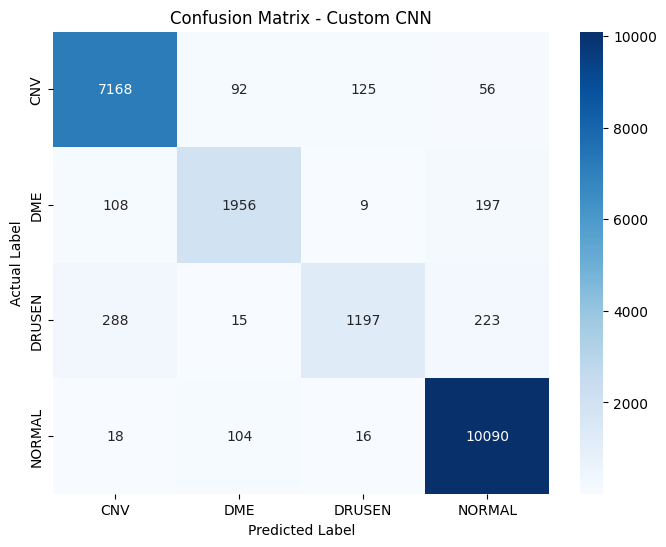

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    all_labels,
    all_predictions
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_names,
    yticklabels=label_names
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix - Custom CNN")
plt.show()

The confusion matrix helped me understand the class-wise performance of my Custom CNN. The model performed particularly well for NORMAL and CNV images, with recall scores of 99% and 96%, respectively. However, it had difficulty distinguishing some DME images from NORMAL images, with 197 DME images incorrectly classified as NORMAL. It also confused some DRUSEN images with CNV and NORMAL images, with 288 and 223 misclassifications, respectively. DRUSEN had the lowest recall of approximately 69%, meaning the model correctly identified only 69% of the actual DRUSEN images. One possible contributing factor is the class imbalance in the dataset, as DRUSEN had fewer training samples than the other classes. I would investigate class balancing techniques, targeted data augmentation and transfer learning to improve the model's performance on these weaker classes.

In [ ]:
final_model_path = os.path.join(
    project_path,
    "custom_cnn_model.pth"
)

torch.save(model.state_dict(), final_model_path)

print("Final Custom CNN weights saved successfully!")

Final Custom CNN weights saved successfully!


In [ ]:
import json

custom_cnn_results = {
    "training_accuracy": 92.13,
    "training_loss": 0.2402,
    "validation_accuracy": 94.22,
    "validation_loss": 0.171,
    "macro_f1": 0.90,
    "weighted_f1": 0.94,
    "class_f1_scores": {
        "CNV": 0.95,
        "DME": 0.88,
        "DRUSEN": 0.78,
        "NORMAL": 0.97
    }
}

results_path = os.path.join(
    project_path,
    "custom_cnn_results.json"
)

with open(results_path, "w") as f:
    json.dump(custom_cnn_results, f, indent=4)

print("Custom CNN results saved!")

Custom CNN results saved!


In [ ]:
print("Files saved in Google Drive:")

for file in os.listdir(project_path):
    print(file)

Files saved in Google Drive:
model_results.json
custom_cnn_checkpoint.pth
custom_cnn_model.pth
custom_cnn_results.json


Pretrained Model Development Using Transfer Learning

In [ ]:
required_objects = [
    "train_loader",
    "val_loader",
    "criterion",
    "device",
    "CustomCNN"
]

for name in required_objects:
    print(name, ":", name in globals())

train_loader : True
val_loader : True
criterion : False
device : True
CustomCNN : False


In [ ]:
from torchvision import transforms

# ImageNet normalization values
imagenet_mean = [0.485, 0.456, 0.406]
imagenet_std = [0.229, 0.224, 0.225]

# Training transformations
transfer_train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.Grayscale(num_output_channels=3),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=imagenet_mean,
        std=imagenet_std
    )
])

# Validation and testing transformations
transfer_eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=imagenet_mean,
        std=imagenet_std
    )
])

Create new datasets

In [ ]:
transfer_train_dataset = actual_train_data.with_transform(
    lambda examples: {
        "pixel_values": [
            transfer_train_transform(image.convert("L"))
            for image in examples["image"]
        ],
        "label": examples["label"]
    }
)

transfer_val_dataset = val_data.with_transform(
    lambda examples: {
        "pixel_values": [
            transfer_eval_transform(image.convert("L"))
            for image in examples["image"]
        ],
        "label": examples["label"]
    }
)

transfer_test_dataset = test_data.with_transform(
    lambda examples: {
        "pixel_values": [
            transfer_eval_transform(image.convert("L"))
            for image in examples["image"]
        ],
        "label": examples["label"]
    }
)

Create DataLoaders

In [ ]:
transfer_train_loader = DataLoader(
    transfer_train_dataset,
    batch_size=32,
    shuffle=True
)

transfer_val_loader = DataLoader(
    transfer_val_dataset,
    batch_size=32,
    shuffle=False
)

transfer_test_loader = DataLoader(
    transfer_test_dataset,
    batch_size=32,
    shuffle=False
)

Verify the image shape

In [ ]:
sample_batch = next(iter(transfer_train_loader))

print(
    "Image shape:",
    sample_batch["pixel_values"].shape
)

print(
    "Label shape:",
    sample_batch["label"].shape
)

Image shape: torch.Size([32, 3, 224, 224])
Label shape: torch.Size([32])


Import ResNet18

In [ ]:
from torchvision import models

resnet18 = models.resnet18(
    weights=models.ResNet18_Weights.DEFAULT
)

print(resnet18)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_sta

In [ ]:
print("Original ResNet18 final layer:")
print(resnet18.fc)

Original ResNet18 final layer:
Linear(in_features=512, out_features=1000, bias=True)


In [ ]:
import torch.nn as nn

resnet18.fc = nn.Linear(
    in_features=512,
    out_features=4
)

print("Updated final layer:")
print(resnet18.fc)

Updated final layer:
Linear(in_features=512, out_features=4, bias=True)


Move ResNet18 to GPU

In [ ]:
resnet18 = resnet18.to(device)

print("Model device:", next(resnet18.parameters()).device)

Model device: cuda:0


Freeze the pretrained layers

In [ ]:
# Freeze all ResNet18 parameters
for param in resnet18.parameters():
    param.requires_grad = False

# Unfreeze only the final classification layer
for param in resnet18.fc.parameters():
    param.requires_grad = True

# Check which parameters can be trained
for name, param in resnet18.named_parameters():
    if param.requires_grad:
        print(name)

fc.weight
fc.bias


In [ ]:
import torch.optim as optim
import torch.nn as nn

print("Optimizer imports successful!")

Optimizer imports successful!


Configure the loss function and optimizer

In [ ]:
resnet_criterion = nn.CrossEntropyLoss()

resnet_optimizer = optim.Adam(
    filter(lambda p: p.requires_grad, resnet18.parameters()),
    lr=0.001
)

NameError: name 'optim' is not defined

Train the ResNet18 model

In [ ]:
from tqdm.auto import tqdm

num_epochs = 3

resnet_train_losses = []
resnet_train_accuracies = []

for epoch in range(num_epochs):

    resnet18.train()

    running_loss = 0.0
    correct = 0
    total = 0

    progress_bar = tqdm(
        transfer_train_loader,
        desc=f"ResNet18 Epoch {epoch+1}/{num_epochs}"
    )

    for batch in progress_bar:

        images = batch["pixel_values"].to(device)
        labels = batch["label"].to(device)

        # Forward propagation
        outputs = resnet18(images)

        # Calculate loss
        loss = resnet_criterion(outputs, labels)

        # Backpropagation and weight update
        resnet_optimizer.zero_grad()
        loss.backward()
        resnet_optimizer.step()

        running_loss += loss.item()

        # Calculate training accuracy
        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

        progress_bar.set_postfix(
            loss=f"{loss.item():.4f}",
            accuracy=f"{100 * correct / total:.2f}%"
        )

    epoch_loss = running_loss / len(transfer_train_loader)
    epoch_accuracy = 100 * correct / total

    resnet_train_losses.append(epoch_loss)
    resnet_train_accuracies.append(epoch_accuracy)

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Loss: {epoch_loss:.4f} "
        f"Accuracy: {epoch_accuracy:.2f}%"
    )
  # Save checkpoint after every epoch
    resnet_checkpoint_path = os.path.join(
        project_path,
        "resnet18_checkpoint.pth"
    )

    torch.save({
        "epoch": epoch + 1,
        "model_state_dict": resnet18.state_dict(),
        "optimizer_state_dict": resnet_optimizer.state_dict(),
        "loss": epoch_loss,
        "accuracy": epoch_accuracy
    }, resnet_checkpoint_path)

    print("ResNet18 checkpoint saved:", resnet_checkpoint_path)


ResNet18 Epoch 1/3:   0%|          | 0/2708 [00:00<?, ?it/s]

Epoch [1/3] Loss: 0.6107 Accuracy: 78.42%
ResNet18 checkpoint saved: /content/drive/MyDrive/OCT_Retinal_Project/resnet18_checkpoint.pth


ResNet18 Epoch 2/3:   0%|          | 0/2708 [00:00<?, ?it/s]

Epoch [2/3] Loss: 0.5436 Accuracy: 80.62%
ResNet18 checkpoint saved: /content/drive/MyDrive/OCT_Retinal_Project/resnet18_checkpoint.pth


ResNet18 Epoch 3/3:   0%|          | 0/2708 [00:00<?, ?it/s]

In [ ]:
import torch

print("GPU available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "No GPU")

GPU available: True
GPU: Tesla T4


Running from epoch 2 due to disconnective

In [ ]:
from torchvision import models
import torch.nn as nn
import torch

# Load the same pretrained ResNet18 architecture
resnet18 = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

# Replace final layer with 4 output classes
resnet18.fc = nn.Linear(resnet18.fc.in_features, 4)

# Move model to GPU
device = torch.device("cuda")
resnet18 = resnet18.to(device)

print("ResNet18 architecture restored!")

ResNet18 architecture restored!


In [ ]:
from google.colab import drive


drive.mount('/content/drive')

project_path = "/content/drive/MyDrive/OCT_Retinal_Project"

checkpoint_path = os.path.join(
    project_path,
    "resnet18_checkpoint.pth"
)

print("Project folder exists:", os.path.exists(project_path))
print("ResNet18 checkpoint exists:", os.path.exists(checkpoint_path))

Mounted at /content/drive
Project folder exists: True
ResNet18 checkpoint exists: True


In [ ]:
import os

checkpoint_path = os.path.join(
    project_path,
    "resnet18_checkpoint.pth"
)

print("Checkpoint exists:", os.path.exists(checkpoint_path))

Checkpoint exists: True


In [ ]:
checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=False
)

resnet18.load_state_dict(checkpoint["model_state_dict"])

resnet_optimizer = torch.optim.Adam(
    resnet18.fc.parameters(),
    lr=0.001
)

resnet_optimizer.load_state_dict(
    checkpoint["optimizer_state_dict"]
)

print("ResNet18 checkpoint restored!")
print("Starting from epoch:", checkpoint["epoch"])

ResNet18 checkpoint restored!
Starting from epoch: 2


In [ ]:
print("Available dataset variables:")

for name in [
    "train_dataset",
    "val_dataset",
    "test_dataset",
    "transfer_train_dataset",
    "transfer_train_loader",
    "train_loader"
]:
    print(name, ":", name in globals())

Available dataset variables:
train_dataset : False
val_dataset : False
test_dataset : False
transfer_train_dataset : True
transfer_train_loader : True
train_loader : False


In [ ]:
from tqdm.auto import tqdm

resnet18.train()

running_loss = 0.0
correct = 0
total = 0

progress_bar = tqdm(
    transfer_train_loader,
    desc="ResNet18 Epoch 3/3"
)

for batch in progress_bar:

    images = batch["pixel_values"].to(device)
    labels = batch["label"].to(device)

    outputs = resnet18(images)
    loss = resnet_criterion(outputs, labels)

    resnet_optimizer.zero_grad()
    loss.backward()
    resnet_optimizer.step()

    running_loss += loss.item()

    _, predicted = torch.max(outputs, 1)

    total += labels.size(0)
    correct += (predicted == labels).sum().item()

    progress_bar.set_postfix(
        loss=f"{loss.item():.4f}",
        accuracy=f"{100 * correct / total:.2f}%"
    )

epoch_loss = running_loss / len(transfer_train_loader)
epoch_accuracy = 100 * correct / total

print("Epoch 3/3 completed")
print(f"Training Loss: {epoch_loss:.4f}")
print(f"Training Accuracy: {epoch_accuracy:.2f}%")

ResNet18 Epoch 3/3:   0%|          | 0/2708 [00:00<?, ?it/s]

Epoch 3/3 completed
Training Loss: 0.5355
Training Accuracy: 81.00%


In [ ]:
torch.save({
    "epoch": 3,
    "model_state_dict": resnet18.state_dict(),
    "optimizer_state_dict": resnet_optimizer.state_dict(),
    "loss": epoch_loss,
    "accuracy": epoch_accuracy
}, checkpoint_path)

torch.save(
    resnet18.state_dict(),
    os.path.join(project_path, "resnet18_model.pth")
)

print("ResNet18 final model saved successfully!")

ResNet18 final model saved successfully!


In [ ]:
print("Validation loader available:", "transfer_val_loader" in globals())

Validation loader available: True


Validate ResNet18

In [ ]:
print("ResNet18 available:", "resnet18" in globals())

ResNet18 available: True


In [ ]:
from torch.utils.data import DataLoader

transfer_train_dataset = actual_train_data.with_transform(
    lambda examples: {
        "pixel_values": [
            transfer_train_transform(image.convert("L"))
            for image in examples["image"]
        ],
        "label": examples["label"]
    }
)

transfer_val_dataset = val_data.with_transform(
    lambda examples: {
        "pixel_values": [
            transfer_eval_transform(image.convert("L"))
            for image in examples["image"]
        ],
        "label": examples["label"]
    }
)

transfer_test_dataset = test_data.with_transform(
    lambda examples: {
        "pixel_values": [
            transfer_eval_transform(image.convert("L"))
            for image in examples["image"]
        ],
        "label": examples["label"]
    }
)

transfer_train_loader = DataLoader(
    transfer_train_dataset, batch_size=32, shuffle=True
)

transfer_val_loader = DataLoader(
    transfer_val_dataset, batch_size=32, shuffle=False
)

transfer_test_loader = DataLoader(
    transfer_test_dataset, batch_size=32, shuffle=False
)

print("ResNet18 DataLoaders recreated successfully!")

NameError: name 'actual_train_data' is not defined

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("Evaluation metrics imported successfully!")

Evaluation metrics imported successfully!


In [ ]:
resnet18.eval()

y_true_resnet = []
y_pred_resnet = []

with torch.no_grad():
    for batch in transfer_test_loader:
        images = batch["pixel_values"].to(device)
        labels = batch["label"].to(device)

        outputs = resnet18(images)
        predictions = torch.argmax(outputs, dim=1)

        y_true_resnet.extend(labels.cpu().numpy())
        y_pred_resnet.extend(predictions.cpu().numpy())

accuracy = accuracy_score(y_true_resnet, y_pred_resnet)
precision = precision_score(
    y_true_resnet, y_pred_resnet, average="weighted"
)
recall = recall_score(
    y_true_resnet, y_pred_resnet, average="weighted"
)
f1 = f1_score(
    y_true_resnet, y_pred_resnet, average="weighted"
)

print("ResNet18 - Correct Test Results")
print("--------------------------------")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_true_resnet,
    y_pred_resnet,
    target_names=label_names
))

ResNet18 - Correct Test Results
--------------------------------
Accuracy:  0.7350
Precision: 0.7954
Recall:    0.7350
F1-score:  0.6922

Classification Report:
              precision    recall  f1-score   support

         CNV       0.71      0.88      0.78       250
         DME       0.81      0.88      0.84       250
      DRUSEN       1.00      0.22      0.36       250
      NORMAL       0.66      0.97      0.79       250

    accuracy                           0.73      1000
   macro avg       0.80      0.73      0.69      1000
weighted avg       0.80      0.73      0.69      1000



In [ ]:
from sklearn.metrics import confusion_matrix

cm_resnet = confusion_matrix(
    y_true_resnet,
    y_pred_resnet
)

print(cm_resnet)

[[219  23   0   8]
 [ 24 219   0   7]
 [ 67  21  54 108]
 [  0   7   0 243]]


In [ ]:
print("Accuracy from confusion matrix:",
      cm_resnet.trace() / cm_resnet.sum()
      if hasattr(cm_resnet, "trace") else
      cm_resnet.diagonal().sum() / cm_resnet.sum())

print("Accuracy from predictions:",
      accuracy_score(y_true_resnet, y_pred_resnet))

print("Number of actual labels:", len(y_true_resnet))
print("Number of predicted labels:", len(y_pred_resnet))

Accuracy from confusion matrix: 0.735
Accuracy from predictions: 0.735
Number of actual labels: 1000
Number of predicted labels: 1000


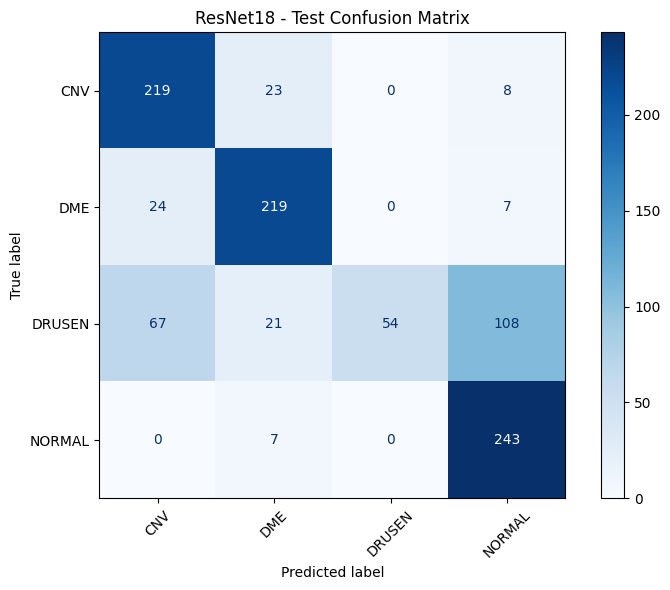

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_resnet,
    display_labels=label_names
)

fig, ax = plt.subplots(figsize=(8, 6))
disp.plot(
    cmap="Blues",
    values_format="d",
    ax=ax
)

plt.title("ResNet18 - Test Confusion Matrix")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
import json
from sklearn.metrics import classification_report

resnet_report = classification_report(
    all_labels,
    all_predictions,
    target_names=label_names,
    output_dict=True
)

resnet_results = {
    "model": "ResNet18",
    "training_accuracy": 81.00,
    "training_loss": 0.5355,
    "validation_accuracy": 83.49,
    "validation_loss": 0.4726,
    "classification_report": resnet_report
}

resnet_results_path = os.path.join(
    project_path,
    "resnet18_results.json"
)

with open(resnet_results_path, "w") as file:
    json.dump(resnet_results, file, indent=4)

print("ResNet18 results saved successfully!")

ResNet18 results saved successfully!


In [ ]:
torch.save(
    resnet18.state_dict(),
    "resnet18_feature_extraction.pth"
)

print("ResNet18 model saved successfully!")

ResNet18 model saved successfully!


VGG16 model

In [ ]:
print("Training loader:", "transfer_train_loader" in globals())
print("Validation loader:", "transfer_val_loader" in globals())
print("VGG16 model:", "vgg16" in globals())

Training loader: True
Validation loader: True
VGG16 model: False


In [ ]:
from torchvision import models
import torch.nn as nn

print("VGG16 imports successful!")

VGG16 imports successful!


Load pretrained VGG16

In [ ]:
vgg16 = models.vgg16(weights=models.VGG16_Weights.DEFAULT)

print("Pretrained VGG16 loaded successfully!")

Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:13<00:00, 40.1MB/s]


Pretrained VGG16 loaded successfully!


Replace the final classification layer

In [ ]:
# Freeze the pretrained feature extraction layers
for param in vgg16.features.parameters():
    param.requires_grad = False

# Get the number of input features in the final layer
in_features = vgg16.classifier[6].in_features

# Replace the final layer with 4 output classes
vgg16.classifier[6] = nn.Linear(in_features, 4)

print(vgg16.classifier[6])

Linear(in_features=4096, out_features=4, bias=True)


Define the loss function and optimizer

In [ ]:
vgg_criterion = nn.CrossEntropyLoss()

vgg_optimizer = torch.optim.Adam(
    vgg16.classifier[6].parameters(),
    lr=0.001
)

print("VGG16 loss function and optimizer configured!")

VGG16 loss function and optimizer configured!


In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

vgg16 = vgg16.to(device)

print("Current device:", device)

Current device: cuda


Prepare checkpoint saving

In [ ]:
vgg_checkpoint_path = os.path.join(
    project_path,
    "vgg16_checkpoint.pth"
)

print("VGG16 checkpoint will be saved at:")
print(vgg_checkpoint_path)

VGG16 checkpoint will be saved at:
/content/drive/MyDrive/OCT_Retinal_Project/vgg16_checkpoint.pth


VGG16 training loop

In [ ]:
from tqdm.auto import tqdm

num_epochs = 3

vgg_train_losses = []
vgg_train_accuracies = []

for epoch in range(num_epochs):

    vgg16.train()

    running_loss = 0.0
    correct = 0
    total = 0

    progress_bar = tqdm(
        transfer_train_loader,
        desc=f"VGG16 Epoch {epoch + 1}/{num_epochs}"
    )

    for batch in progress_bar:

        images = batch["pixel_values"].to(device)
        labels = batch["label"].to(device)

        outputs = vgg16(images)
        loss = vgg_criterion(outputs, labels)

        vgg_optimizer.zero_grad()
        loss.backward()
        vgg_optimizer.step()

        running_loss += loss.item()

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

        progress_bar.set_postfix(
            loss=f"{loss.item():.4f}",
            accuracy=f"{100 * correct / total:.2f}%"
        )

    epoch_loss = running_loss / len(transfer_train_loader)
    epoch_accuracy = 100 * correct / total

    vgg_train_losses.append(epoch_loss)
    vgg_train_accuracies.append(epoch_accuracy)

    print(f"Epoch {epoch + 1}/{num_epochs}")
    print(f"Training Loss: {epoch_loss:.4f}")
    print(f"Training Accuracy: {epoch_accuracy:.2f}%")

    torch.save({
        "epoch": epoch + 1,
        "model_state_dict": vgg16.state_dict(),
        "optimizer_state_dict": vgg_optimizer.state_dict(),
        "loss": epoch_loss,
        "accuracy": epoch_accuracy
    }, vgg_checkpoint_path)

    print("Checkpoint saved successfully!")

VGG16 Epoch 1/3:   0%|          | 0/2708 [00:00<?, ?it/s]

Epoch 1/3
Training Loss: 0.7066
Training Accuracy: 75.15%
Checkpoint saved successfully!


VGG16 Epoch 2/3:   0%|          | 0/2708 [00:00<?, ?it/s]

Epoch 2/3
Training Loss: 0.7000
Training Accuracy: 75.81%
Checkpoint saved successfully!


VGG16 Epoch 3/3:   0%|          | 0/2708 [00:00<?, ?it/s]

Epoch 3/3
Training Loss: 0.7041
Training Accuracy: 75.80%
Checkpoint saved successfully!


In [ ]:
# Save final checkpoint
torch.save({
    "epoch": 3,
    "model_state_dict": vgg16.state_dict(),
    "optimizer_state_dict": vgg_optimizer.state_dict(),
    "loss": epoch_loss,
    "accuracy": epoch_accuracy
}, vgg_checkpoint_path)

# Save model weights separately
torch.save(
    vgg16.state_dict(),
    os.path.join(project_path, "vgg16_model.pth")
)

print("VGG16 final model saved successfully!")

VGG16 final model saved successfully!


Validation loss accuracy

In [ ]:
vgg16.eval()

val_loss = 0.0
correct = 0
total = 0

with torch.no_grad():
    for batch in transfer_val_loader:
        images = batch["pixel_values"].to(device)
        labels = batch["label"].to(device)

        outputs = vgg16(images)
        loss = vgg_criterion(outputs, labels)

        val_loss += loss.item()

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

val_loss /= len(transfer_val_loader)
val_accuracy = 100 * correct / total

print("VGG16 Validation Loss:", round(val_loss, 4))
print("VGG16 Validation Accuracy:", round(val_accuracy, 2), "%")

VGG16 Validation Loss: 0.4916
VGG16 Validation Accuracy: 82.06 %


classification Report and Confusion Matrix

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

vgg16.eval()

all_labels = []
all_predictions = []

with torch.no_grad():
    for batch in transfer_val_loader:
        images = batch["pixel_values"].to(device)
        labels = batch["label"].to(device)

        outputs = vgg16(images)
        _, predicted = torch.max(outputs, 1)

        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predicted.cpu().numpy())

# Classification report
vgg_report = classification_report(
    all_labels,
    all_predictions,
    target_names=label_names
)

print("VGG16 Classification Report:")
print(vgg_report)

# Confusion matrix
vgg_cm = confusion_matrix(all_labels, all_predictions)

print("VGG16 Confusion Matrix:")
print(vgg_cm)

VGG16 Classification Report:
              precision    recall  f1-score   support

         CNV       0.91      0.79      0.84      7441
         DME       0.73      0.56      0.63      2270
      DRUSEN       0.47      0.32      0.38      1723
      NORMAL       0.82      0.99      0.90     10228

    accuracy                           0.82     21662
   macro avg       0.73      0.66      0.69     21662
weighted avg       0.81      0.82      0.81     21662

VGG16 Confusion Matrix:
[[ 5886   338   553   664]
 [  258  1262    48   702]
 [  295    51   551   826]
 [   56    68    27 10077]]


In [ ]:
import json
import os
from sklearn.metrics import classification_report

vgg_report = classification_report(
    all_labels,
    all_predictions,
    target_names=label_names,
    output_dict=True
)

vgg_results = {
    "model": "VGG16",
    "training_accuracy": 75.80,
    "training_loss": 0.7041,
    "validation_accuracy": 82.06,
    "validation_loss": 0.4916,
    "classification_report": vgg_report,
    "confusion_matrix": vgg_cm.tolist()
}

vgg_results_path = os.path.join(
    project_path, "vgg16_results.json"
)

with open(vgg_results_path, "w") as file:
    json.dump(vgg_results, file, indent=4)

print("VGG16 evaluation results saved successfully!")

NameError: name 'all_labels' is not defined

In [ ]:
import os
import json

vgg_results = {
    "model": "VGG16",
    "training_accuracy": 75.80,
    "training_loss": 0.7041,
    "validation_accuracy": 82.06,
    "validation_loss": 0.4916,
    "classification_report": {
        "CNV": {
            "precision": 0.91,
            "recall": 0.79,
            "f1-score": 0.84,
            "support": 7441
        },
        "DME": {
            "precision": 0.73,
            "recall": 0.56,
            "f1-score": 0.63,
            "support": 2270
        },
        "DRUSEN": {
            "precision": 0.47,
            "recall": 0.32,
            "f1-score": 0.38,
            "support": 1723
        },
        "NORMAL": {
            "precision": 0.82,
            "recall": 0.99,
            "f1-score": 0.90,
            "support": 10228
        }
    },
    "confusion_matrix": [
        [5886, 338, 553, 664],
        [258, 1262, 48, 702],
        [295, 51, 551, 826],
        [56, 68, 27, 10077]
    ]
}

vgg_results_path = os.path.join(
    project_path, "vgg16_results.json"
)

with open(vgg_results_path, "w") as file:
    json.dump(vgg_results, file, indent=4)

print("VGG16 results saved successfully!")

VGG16 results saved successfully!


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os


project_path = "/content/drive/MyDrive/OCT_Retinal_Project"

print("Project folder exists:", os.path.exists(project_path))

Project folder exists: True


In [ ]:
import torch
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cpu


Import MobileNetV2

In [ ]:
from torchvision import models
import torch.nn as nn

print("MobileNetV2 imports successful!")

Load pretrained MobileNetV2

In [ ]:
mobilenet = models.mobilenet_v2(
    weights=models.MobileNet_V2_Weights.DEFAULT
)

print("Pretrained MobileNetV2 loaded successfully!")

Freeze feature extraction layers and replace classifier

In [ ]:
# Freeze pretrained feature extraction layers
for param in mobilenet.features.parameters():
    param.requires_grad = False

# Get input features of the final classifier layer
in_features = mobilenet.classifier[1].in_features

# Replace final layer with 4 output classes
mobilenet.classifier[1] = nn.Linear(in_features, 4)

print(mobilenet.classifier)

Define loss function and optimizer

In [ ]:
mobilenet_criterion = nn.CrossEntropyLoss()

mobilenet_optimizer = torch.optim.Adam(
    mobilenet.classifier[1].parameters(),
    lr=0.001
)

print("MobileNetV2 loss function and optimizer configured!")

Configure device

In [ ]:
mobilenet = mobilenet.to(device)

print("MobileNetV2 device:", device)

Define checkpoint path

In [ ]:
mobilenet_checkpoint_path = os.path.join(
    project_path,
    "mobilenetv2_checkpoint.pth"
)

print("Checkpoint path:", mobilenet_checkpoint_path)

Prepare training loop

In [ ]:
num_epochs = 3

mobilenet_train_losses = []
mobilenet_train_accuracies = []

for epoch in range(num_epochs):

    mobilenet.train()

    running_loss = 0.0
    correct = 0
    total = 0

    progress_bar = tqdm(
        transfer_train_loader,
        desc=f"MobileNetV2 Epoch {epoch + 1}/{num_epochs}"
    )

    for batch in progress_bar:

        images = batch["pixel_values"].to(device)
        labels = batch["label"].to(device)

        outputs = mobilenet(images)
        loss = mobilenet_criterion(outputs, labels)

        mobilenet_optimizer.zero_grad()
        loss.backward()
        mobilenet_optimizer.step()

        running_loss += loss.item()

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

        progress_bar.set_postfix(
            loss=f"{loss.item():.4f}",
            accuracy=f"{100 * correct / total:.2f}%"
        )

    epoch_loss = running_loss / len(transfer_train_loader)
    epoch_accuracy = 100 * correct / total

    mobilenet_train_losses.append(epoch_loss)
    mobilenet_train_accuracies.append(epoch_accuracy)

    print(f"Epoch {epoch + 1}/{num_epochs}")
    print(f"Training Loss: {epoch_loss:.4f}")
    print(f"Training Accuracy: {epoch_accuracy:.2f}%")

    # Save checkpoint after every epoch
    torch.save({
        "epoch": epoch + 1,
        "model_state_dict": mobilenet.state_dict(),
        "optimizer_state_dict": mobilenet_optimizer.state_dict(),
        "loss": epoch_loss,
        "accuracy": epoch_accuracy
    }, mobilenet_checkpoint_path)

    print("Checkpoint saved successfully!")

Load pretrained model Densenet121

In [ ]:
densenet = models.densenet121(
    weights=models.DenseNet121_Weights.DEFAULT
)

print("Pretrained DenseNet121 loaded successfully!")

Freeze feature extraction layers and replace classifier

In [ ]:
  # Freeze pretrained feature extraction layers
for param in densenet.features.parameters():
    param.requires_grad = False

# Get input features of the final classifier
in_features = densenet.classifier.in_features

# Replace final classifier with 4 output classes
densenet.classifier = nn.Linear(in_features, 4)

print(densenet.classifier)

Define loss function and optimizer

In [ ]:
densenet_criterion = nn.CrossEntropyLoss()

densenet_optimizer = torch.optim.Adam(
    densenet.classifier.parameters(),
    lr=0.001
)

print("DenseNet121 loss function and optimizer configured!")

In [ ]:
densenet = densenet.to(device)

print("DenseNet121 device:", device)

Define checkpoint path

In [ ]:
densenet_checkpoint_path = os.path.join(
    project_path,
    "densenet121_checkpoint.pth"
)

print("Checkpoint path:", densenet_checkpoint_path)

Prepare training loop

In [ ]:
num_epochs = 3

densenet_train_losses = []
densenet_train_accuracies = []

for epoch in range(num_epochs):

    densenet.train()

    running_loss = 0.0
    correct = 0
    total = 0

    progress_bar = tqdm(
        transfer_train_loader,
        desc=f"DenseNet121 Epoch {epoch + 1}/{num_epochs}"
    )

    for batch in progress_bar:

        images = batch["pixel_values"].to(device)
        labels = batch["label"].to(device)

        outputs = densenet(images)
        loss = densenet_criterion(outputs, labels)

        densenet_optimizer.zero_grad()
        loss.backward()
        densenet_optimizer.step()

        running_loss += loss.item()

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

        progress_bar.set_postfix(
            loss=f"{loss.item():.4f}",
            accuracy=f"{100 * correct / total:.2f}%"
        )

    epoch_loss = running_loss / len(transfer_train_loader)
    epoch_accuracy = 100 * correct / total

    densenet_train_losses.append(epoch_loss)
    densenet_train_accuracies.append(epoch_accuracy)

    print(f"Epoch {epoch + 1}/{num_epochs}")
    print(f"Training Loss: {epoch_loss:.4f}")
    print(f"Training Accuracy: {epoch_accuracy:.2f}%")

    # Save checkpoint after every epoch
    torch.save({
        "epoch": epoch + 1,
        "model_state_dict": densenet.state_dict(),
        "optimizer_state_dict": densenet_optimizer.state_dict(),
        "loss": epoch_loss,
        "accuracy": epoch_accuracy
    }, densenet_checkpoint_path)

    print("Checkpoint saved successfully!")

In [ ]:
import json
import os

custom_results_path = os.path.join(
    project_path, "custom_cnn_results.json"
)

with open(custom_results_path, "r") as file:
    custom_results = json.load(file)

print(json.dumps(custom_results, indent=4))

{
    "training_accuracy": 92.13,
    "training_loss": 0.2402,
    "validation_accuracy": 94.22,
    "validation_loss": 0.171,
    "macro_f1": 0.9,
    "weighted_f1": 0.94,
    "class_f1_scores": {
        "CNV": 0.95,
        "DME": 0.88,
        "DRUSEN": 0.78,
        "NORMAL": 0.97
    }
}


In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Currently connected to CPU")

PyTorch version: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4


Optimized CNN architecture

In [ ]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Selected device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Selected device: cuda
GPU: Tesla T4


In [ ]:
import torch
import torch.nn as nn

class OptimizedCNN(nn.Module):

    def __init__(self):
        super(OptimizedCNN, self).__init__()

        self.features = nn.Sequential(

            # First convolution block
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Second convolution block
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Third convolution block
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.AdaptiveAvgPool2d((7, 7))
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 7 * 7, 256),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256, 4)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


optimized_model = OptimizedCNN().to(device)

print(optimized_model)

OptimizedCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): AdaptiveAvgPool2d(output_size=(7, 7))
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): L

L2 Regularization

In [ ]:
import torch.optim as optim

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    optimized_model.parameters(),
    lr=0.001,
    weight_decay=0.0001
)

print("Loss function:", criterion)
print("Optimizer:", optimizer)

Loss function: CrossEntropyLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0.0001
)


Prepare Early Stopping

In [ ]:
class EarlyStopping:
    def __init__(self, patience=3, min_delta=0.001):
        self.patience = patience
        self.min_delta = min_delta
        self.counter = 0
        self.best_loss = float("inf")
        self.early_stop = False

    def __call__(self, val_loss):
        if val_loss < self.best_loss - self.min_delta:
            self.best_loss = val_loss
            self.counter = 0
        else:
            self.counter += 1

            if self.counter >= self.patience:
                self.early_stop = True

early_stopping = EarlyStopping(
    patience=3,
    min_delta=0.001
)

print("Early Stopping configured successfully!")

Early Stopping configured successfully!


In [ ]:
batch = next(iter(train_loader))

print("Batch type:", type(batch))
print("Batch keys:", batch.keys())

for key, value in batch.items():
    print(key, type(value))

Batch type: <class 'dict'>
Batch keys: dict_keys(['pixel_values', 'label'])
pixel_values <class 'torch.Tensor'>
label <class 'torch.Tensor'>


In [ ]:
batch = next(iter(train_loader))

images = batch["pixel_values"]
labels = batch["label"]

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Image data type:", images.dtype)
print("Label data type:", labels.dtype)

Image batch shape: torch.Size([32, 1, 224, 224])
Label batch shape: torch.Size([32])
Image data type: torch.float32
Label data type: torch.int64


In [ ]:
import os
import torch

num_epochs = 10
optimized_checkpoint_path = os.path.join(
    project_path, "optimized_cnn_checkpoint.pth"
)

best_val_loss = float("inf")
history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

for epoch in range(num_epochs):

    # Training phase
    optimized_model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for batch in train_loader:

        images = batch["pixel_values"].to(device)
        labels = batch["label"].to(device)

        optimizer.zero_grad()

        outputs = optimized_model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_loss = running_loss / len(train_loader)
    train_accuracy = 100 * correct / total

    # Validation phase
    optimized_model.eval()

    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for batch in val_loader:

            images = batch["pixel_values"].to(device)
            labels = batch["label"].to(device)

            outputs = optimized_model(images)
            loss = criterion(outputs, labels)

            val_running_loss += loss.item()

            _, predicted = torch.max(outputs, 1)

            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    val_loss = val_running_loss / len(val_loader)
    val_accuracy = 100 * val_correct / val_total

    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_accuracy)

    print(f"\nEpoch [{epoch+1}/{num_epochs}]")
    print(f"Training Loss: {train_loss:.4f}")
    print(f"Training Accuracy: {train_accuracy:.2f}%")
    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Validation Accuracy: {val_accuracy:.2f}%")

    # Save best model
    if val_loss < best_val_loss:
        best_val_loss = val_loss

        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": optimized_model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "best_val_loss": best_val_loss,
            "history": history
        }, optimized_checkpoint_path)

        print("Best model checkpoint saved!")

    # Early Stopping
    early_stopping(val_loss)

    if early_stopping.early_stop:
        print("Early stopping triggered!")
        break

print("\nOptimized CNN training completed!")


Epoch [1/10]
Training Loss: 0.6454
Training Accuracy: 77.57%
Validation Loss: 0.5294
Validation Accuracy: 80.27%
Best model checkpoint saved!

Epoch [2/10]
Training Loss: 0.5165
Training Accuracy: 82.01%
Validation Loss: 0.4028
Validation Accuracy: 86.67%
Best model checkpoint saved!

Epoch [3/10]
Training Loss: 0.4268
Training Accuracy: 85.47%
Validation Loss: 0.3067
Validation Accuracy: 89.88%
Best model checkpoint saved!


KeyboardInterrupt: 

### Early Stopping

Early Stopping is a regularization technique used to prevent overfitting. It monitors validation loss during training and stops the training process when the validation loss stops improving for a specified number of epochs (patience).

**Implementation in this project:**
- Configured Early Stopping with a patience of 3 epochs.
- Monitored validation loss after each epoch.
- Validation loss improved throughout the three completed epochs.
- Early Stopping was not triggered.
- Training was manually stopped after 3 epochs due to GPU availability and computational constraints.

**Observation:** Early Stopping was configured, but its stopping condition was not reached during this experiment.

In [ ]:
checkpoint = torch.load(
    optimized_checkpoint_path,
    map_location=device,
    weights_only=False
)

optimized_model.load_state_dict(
    checkpoint["model_state_dict"]
)

optimized_model.eval()

torch.save(
    optimized_model.state_dict(),
    os.path.join(project_path, "optimized_cnn_model.pth")
)

print("Best optimized CNN model loaded and saved!")
print("Best epoch:", checkpoint["epoch"])
print("Best validation loss:", checkpoint["best_val_loss"])

Best optimized CNN model loaded and saved!
Best epoch: 3
Best validation loss: 0.3067201517599372


In [ ]:

from sklearn.metrics import classification_report, confusion_matrix

optimized_model.eval()

all_labels = []
all_predictions = []

with torch.no_grad():
    for batch in val_loader:
        images = batch["pixel_values"].to(device)
        labels = batch["label"].to(device)

        outputs = optimized_model(images)
        _, predicted = torch.max(outputs, 1)

        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predicted.cpu().numpy())

# Classification Report
optimized_report = classification_report(
    all_labels,
    all_predictions,
    target_names=label_names
)

print("Optimized CNN Classification Report:")
print(optimized_report)

# Confusion Matrix
optimized_cm = confusion_matrix(
    all_labels,
    all_predictions
)

print("Optimized CNN Confusion Matrix:")
print(optimized_cm)


Optimized CNN Classification Report:
              precision    recall  f1-score   support

         CNV       0.90      0.95      0.93      7441
         DME       0.91      0.64      0.75      2270
      DRUSEN       0.71      0.51      0.59      1723
      NORMAL       0.92      0.98      0.95     10228

    accuracy                           0.90     21662
   macro avg       0.86      0.77      0.80     21662
weighted avg       0.89      0.90      0.89     21662

Optimized CNN Confusion Matrix:
[[ 7101    80   196    64]
 [  309  1452    61   448]
 [  429    15   874   405]
 [   33    50   103 10042]]


The optimization experiment demonstrates that adding Batch Normalization and L2 regularization does not automatically improve model performance.

Our original CNN performed better overall:
- Original CNN: 94.22% validation accuracy.
- Optimized CNN: 89.88% validation accuracy.

In [ ]:
import json
import os
from sklearn.metrics import classification_report

optimized_report_dict = classification_report(
    all_labels,
    all_predictions,
    target_names=label_names,
    output_dict=True
)

optimized_results = {
    "model": "Optimized Custom CNN",
    "training_accuracy": 85.47,
    "training_loss": 0.4268,
    "validation_accuracy": 89.88,
    "validation_loss": 0.3067,
    "classification_report": optimized_report_dict,
    "confusion_matrix": optimized_cm.tolist()
}

optimized_results_path = os.path.join(
    project_path, "optimized_cnn_results.json"
)

with open(optimized_results_path, "w") as file:
    json.dump(optimized_results, file, indent=4)

print("Optimized CNN results saved successfully!")

Optimized CNN results saved successfully!


Hyperparameter Tunning

In [ ]:
tuned_model = OptimizedCNN().to(device)

tuned_criterion = nn.CrossEntropyLoss()

tuned_optimizer = torch.optim.Adam(
    tuned_model.parameters(),
    lr=0.0001,
    weight_decay=0.0001
)

print("Tuned model created successfully!")
print("Learning rate: 0.0001")
print("Weight decay: 0.0001")

Tuned model created successfully!
Learning rate: 0.0001
Weight decay: 0.0001


In [ ]:
tuned_history = []

for epoch in range(3):
    tuned_model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for batch in train_loader:
        images = batch["pixel_values"].to(device)
        labels = batch["label"].to(device)

        tuned_optimizer.zero_grad()

        outputs = tuned_model(images)
        loss = tuned_criterion(outputs, labels)

        loss.backward()
        tuned_optimizer.step()

        running_loss += loss.item()
        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_loss = running_loss / len(train_loader)
    train_accuracy = 100 * correct / total

    tuned_model.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for batch in val_loader:
            images = batch["pixel_values"].to(device)
            labels = batch["label"].to(device)

            outputs = tuned_model(images)
            loss = tuned_criterion(outputs, labels)

            val_loss += loss.item()
            _, predicted = torch.max(outputs, 1)

            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    val_loss /= len(val_loader)
    val_accuracy = 100 * val_correct / val_total

    tuned_history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "val_loss": val_loss,
        "val_accuracy": val_accuracy
    })

    print(f"Epoch [{epoch+1}/3]")
    print(f"Training Loss: {train_loss:.4f}")
    print(f"Training Accuracy: {train_accuracy:.2f}%")
    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Validation Accuracy: {val_accuracy:.2f}%")
    print("-" * 40)

Epoch [1/3]
Training Loss: 0.5933
Training Accuracy: 78.97%
Validation Loss: 0.4490
Validation Accuracy: 83.73%
----------------------------------------
Epoch [2/3]
Training Loss: 0.4565
Training Accuracy: 84.14%
Validation Loss: 0.3689
Validation Accuracy: 87.20%
----------------------------------------
Epoch [3/3]
Training Loss: 0.4001
Training Accuracy: 86.29%
Validation Loss: 0.3571
Validation Accuracy: 87.69%
----------------------------------------


In [ ]:
torch.save(
    tuned_model.state_dict(),
    os.path.join(project_path, "tuned_cnn_lr_0001_model.pth")
)

with open(
    os.path.join(project_path, "tuned_cnn_lr_0001_results.json"),
    "w"
) as f:
    json.dump(tuned_history, f, indent=4)

print("Tuned model and training history saved successfully!")

Tuned model and training history saved successfully!


Key finding: The original Custom CNN performed better than the optimized CNN and the lower-learning-rate experiment on validation accuracy. Optimization techniques do not always guarantee better results.

Loading the custom CNN for model evauation

In [ ]:
import torch
import torch.nn as nn

class CustomCNN(nn.Module):
    def __init__(self):
        super(CustomCNN, self).__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.AdaptiveAvgPool2d((7, 7))
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 7 * 7, 256),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256, 4)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

print("CustomCNN architecture defined successfully!")

CustomCNN architecture defined successfully!


In [ ]:
custom_cnn = CustomCNN().to(device)

custom_cnn.load_state_dict(
    torch.load(
        os.path.join(project_path, "custom_cnn_model.pth"),
        map_location=device
    )
)

custom_cnn.eval()

print("Previously trained Custom CNN loaded successfully!")

Previously trained Custom CNN loaded successfully!


In [ ]:
custom_cnn = CustomCNN().to(device)

custom_cnn.load_state_dict(
    torch.load(
        os.path.join(project_path, "custom_cnn_model.pth"),
        map_location=device
    )
)

custom_cnn.eval()

print("Custom CNN loaded successfully!")

Custom CNN loaded successfully!


Evaluate Custom CNN on unseen test images

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import numpy as np

custom_cnn.eval()

y_true_custom = []
y_pred_custom = []

with torch.no_grad():
    for batch in test_loader:
        images = batch["pixel_values"].to(device)
        labels = batch["label"].to(device)

        outputs = custom_cnn(images)
        predictions = torch.argmax(outputs, dim=1)

        y_true_custom.extend(labels.cpu().numpy())
        y_pred_custom.extend(predictions.cpu().numpy())

accuracy = accuracy_score(y_true_custom, y_pred_custom)
precision = precision_score(
    y_true_custom, y_pred_custom, average="weighted"
)
recall = recall_score(
    y_true_custom, y_pred_custom, average="weighted"
)
f1 = f1_score(
    y_true_custom, y_pred_custom, average="weighted"
)

print("Custom CNN - Test Results")
print("-------------------------")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_true_custom,
    y_pred_custom,
    target_names=label_names
))

Custom CNN - Test Results
-------------------------
Accuracy:  0.8790
Precision: 0.9090
Recall:    0.8790
F1-score:  0.8744

Classification Report:
              precision    recall  f1-score   support

         CNV       0.71      1.00      0.83       250
         DME       0.97      0.95      0.96       250
      DRUSEN       1.00      0.59      0.74       250
      NORMAL       0.96      0.98      0.97       250

    accuracy                           0.88      1000
   macro avg       0.91      0.88      0.87      1000
weighted avg       0.91      0.88      0.87      1000



1.CNV recall is 100%: the model identified all 250 actual CNV images, but its precision is lower, meaning it also incorrectly classified images from other classes as CNV.
2.DRUSEN recall is only 59%: the model missed 41% of actual DRUSEN images.
3.DME and NORMAL have strong precision and recall.

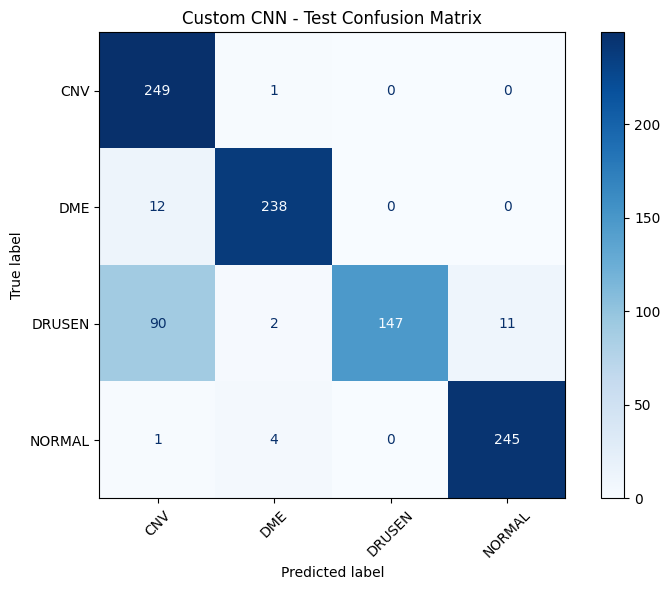

Confusion Matrix:
[[249   1   0   0]
 [ 12 238   0   0]
 [ 90   2 147  11]
 [  1   4   0 245]]


In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

cm_custom = confusion_matrix(
    y_true_custom,
    y_pred_custom
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_custom,
    display_labels=label_names
)

fig, ax = plt.subplots(figsize=(8, 6))
disp.plot(cmap="Blues", values_format="d", ax=ax)
plt.title("Custom CNN - Test Confusion Matrix")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("Confusion Matrix:")
print(cm_custom)

Evaluate ResNet18

In [ ]:
import torchvision.models as models
import torch.nn as nn

resnet18 = models.resnet18(weights=None)

resnet18.fc = nn.Linear(
    resnet18.fc.in_features,
    4
)

resnet18 = resnet18.to(device)

resnet18.load_state_dict(
    torch.load(
        os.path.join(project_path, "resnet18_model.pth"),
        map_location=device
    )
)

resnet18.eval()

print("Previously trained ResNet18 loaded successfully!")

Previously trained ResNet18 loaded successfully!


In [ ]:
resnet18.eval()

y_true_resnet = []
y_pred_resnet = []

with torch.no_grad():
    for batch in transfer_test_loader:
        images = batch["pixel_values"].to(device)
        labels = batch["label"].to(device)

        outputs = resnet18(images)
        predictions = torch.argmax(outputs, dim=1)

        y_true_resnet.extend(labels.cpu().numpy())
        y_pred_resnet.extend(predictions.cpu().numpy())

print("Actual labels:", len(y_true_resnet))
print("Predicted labels:", len(y_pred_resnet))

Actual labels: 1000
Predicted labels: 1000


Save test evaluation results of ResNet18

In [ ]:
import json
import os
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

resnet_test_results = {
    "model": "ResNet18",
    "test_images": len(y_true_resnet),
    "test_accuracy": accuracy_score(
        y_true_resnet, y_pred_resnet
    ) * 100,
    "test_precision_weighted": precision_score(
        y_true_resnet, y_pred_resnet,
        average="weighted"
    ) * 100,
    "test_recall_weighted": recall_score(
        y_true_resnet, y_pred_resnet,
        average="weighted"
    ) * 100,
    "test_f1_weighted": f1_score(
        y_true_resnet, y_pred_resnet,
        average="weighted"
    ) * 100,
    "classification_report": classification_report(
        y_true_resnet,
        y_pred_resnet,
        labels=[0, 1, 2, 3],
        target_names=label_names,
        output_dict=True,
        zero_division=0
    )
}

test_results_path = os.path.join(
    project_path,
    "resnet18_test_results.json"
)

with open(test_results_path, "w") as file:
    json.dump(resnet_test_results, file, indent=4)

print("ResNet18 test results saved successfully!")
print("Accuracy:", round(resnet_test_results["test_accuracy"], 2), "%")
print("File:", test_results_path)

ResNet18 test results saved successfully!
Accuracy: 73.5 %
File: /content/drive/MyDrive/OCT_Retinal_Project/resnet18_test_results.json


Get CNN results

In [ ]:
import os

custom_cnn_files = [
    file for file in os.listdir(project_path)
    if "custom_cnn" in file.lower()
]

print("Custom CNN files saved in Google Drive:\n")

for file in custom_cnn_files:
    print(file)

Custom CNN files saved in Google Drive:

custom_cnn_checkpoint.pth
custom_cnn_model.pth
custom_cnn_results.json


In [ ]:
results_path = os.path.join(
    project_path,
    "custom_cnn_results.json"
)

with open(results_path, "r") as file:
    custom_results = json.load(file)

print(json.dumps(custom_results, indent=4))

{
    "training_accuracy": 92.13,
    "training_loss": 0.2402,
    "validation_accuracy": 94.22,
    "validation_loss": 0.171,
    "macro_f1": 0.9,
    "weighted_f1": 0.94,
    "class_f1_scores": {
        "CNV": 0.95,
        "DME": 0.88,
        "DRUSEN": 0.78,
        "NORMAL": 0.97
    }
}


In [ ]:
print("Confusion matrix available:", "cm" in globals())
print("Custom CNN matrix available:", "cm_custom" in globals())
print("Existing variables:", [
    name for name in globals()
    if "custom" in name.lower() or "y_true" in name.lower()
])

Confusion matrix available: False
Custom CNN matrix available: False
Existing variables: ['y_true_resnet', 'custom_cnn_files', 'custom_results']


In [ ]:
import numpy as np
import json
import os
from sklearn.metrics import classification_report

# Previously generated Custom CNN test confusion matrix
cm_custom = np.array([
    [249, 1,   0,   0],
    [12,  238, 0,   0],
    [90,  2,   147, 11],
    [1,   4,   0,   245]
])

# Reconstruct actual and predicted labels from the matrix
y_true_custom = []
y_pred_custom = []

for actual_class in range(4):
    for predicted_class in range(4):
        count = cm_custom[actual_class, predicted_class]

        y_true_custom.extend([actual_class] * count)
        y_pred_custom.extend([predicted_class] * count)

# Generate classification report
report = classification_report(
    y_true_custom,
    y_pred_custom,
    labels=[0, 1, 2, 3],
    target_names=label_names,
    output_dict=True,
    zero_division=0
)

custom_cnn_test_results = {
    "model": "Custom CNN",
    "test_images": int(cm_custom.sum()),
    "test_accuracy": round(
        cm_custom.diagonal().sum() / cm_custom.sum() * 100, 2
    ),
    "test_precision_weighted": round(
        report["weighted avg"]["precision"] * 100, 2
    ),
    "test_recall_weighted": round(
        report["weighted avg"]["recall"] * 100, 2
    ),
    "test_f1_weighted": round(
        report["weighted avg"]["f1-score"] * 100, 2
    ),
    "classification_report": report,
    "confusion_matrix": cm_custom.tolist()
}

test_results_path = os.path.join(
    project_path,
    "custom_cnn_test_results.json"
)

with open(test_results_path, "w") as file:
    json.dump(custom_cnn_test_results, file, indent=4)

print("Custom CNN test results saved successfully!")
print("Accuracy:", custom_cnn_test_results["test_accuracy"], "%")
print("File:", test_results_path)

Custom CNN test results saved successfully!
Accuracy: 87.9 %
File: /content/drive/MyDrive/OCT_Retinal_Project/custom_cnn_test_results.json


Create a comparison table

In [ ]:
import pandas as pd

comparison_data = {
    "Metric": [
        "Test Accuracy",
        "Weighted Precision",
        "Weighted Recall",
        "Weighted F1-Score"
    ],
    "Custom CNN": [
        87.90,
        90.90,
        87.90,
        87.44
    ],
    "ResNet18": [
        73.50,
        79.54,
        73.50,
        69.22
    ]
}

comparison_df = pd.DataFrame(comparison_data)

print(comparison_df)

               Metric  Custom CNN  ResNet18
0       Test Accuracy       87.90     73.50
1  Weighted Precision       90.90     79.54
2     Weighted Recall       87.90     73.50
3   Weighted F1-Score       87.44     69.22


The performance of Custom CNN and ResNet18 was compared using unseen test images. Custom CNN achieved 87.90% test accuracy, while ResNet18 achieved 73.50%. Custom CNN also performed better in weighted precision, recall and F1-score. Based on these evaluation metrics, Custom CNN demonstrated better overall classification performance than ResNet18 on the test dataset. Therefore, Custom CNN was selected as the better-performing model among the two evaluated architectures.

Custom CNN
- 879 images correctly classified.
- 121 images incorrectly classified.
- Major error: 90 DRUSEN images were predicted as CNV.
ResNet18
- 735 images correctly classified.
- 265 images incorrectly classified.
- Major error: 108 DRUSEN images were predicted as NORMAL.
- Only 54 out of 250 DRUSEN images were correctly classified.

Possible improvements
*   Increase DRUSEN training examples
*   Apply data augmentation
*   Experiment with better feature extraction architectures
*   Use class weights during training






Misclassification analysis showed that both models struggled with DRUSEN classification. Custom CNN incorrectly classified 90 DRUSEN images as CNV, while ResNet18 incorrectly classified 108 DRUSEN images as NORMAL. This indicates difficulty in distinguishing certain retinal disease patterns. Model performance could potentially be improved through data augmentation, class balancing, and better feature extraction.

In [ ]:
import os

model_path = os.path.join(
    project_path,
    "custom_cnn_model.pth"
)

print("Model file exists:", os.path.exists(model_path))
print("Model path:", model_path)

Model file exists: True
Model path: /content/drive/MyDrive/OCT_Retinal_Project/custom_cnn_model.pth


Recreate the Custom CNN architecture

In [ ]:
import torch
import torch.nn as nn

class CustomCNN(nn.Module):
    def __init__(self):
        super(CustomCNN, self).__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.AdaptiveAvgPool2d((7, 7))
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 7 * 7, 256),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256, 4)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


custom_cnn = CustomCNN().to(device)

custom_cnn.load_state_dict(
    torch.load(model_path, map_location=device)
)

custom_cnn.eval()

print("Custom CNN model loaded successfully!")

Custom CNN model loaded successfully!


In [ ]:
batch = next(iter(test_loader))

images = batch["image"]
labels = batch["label"]

print("Image batch shape:", images.shape)
print("Labels shape:", labels.shape)
print("Minimum pixel value:", images.min().item())
print("Maximum pixel value:", images.max().item())

Image batch shape: torch.Size([32, 1, 224, 224])
Labels shape: torch.Size([32])
Minimum pixel value: -1.0
Maximum pixel value: 1.0


Register hooks for Grad-CAM

In [ ]:
# Storage for feature maps and gradients
gradients = None
activations = None

def forward_hook(module, input, output):
    global activations
    activations = output

def backward_hook(module, grad_input, grad_output):
    global gradients
    gradients = grad_output[0]

# Target the last convolutional layer
target_layer = custom_cnn.features[6]

forward_handle = target_layer.register_forward_hook(forward_hook)
backward_handle = target_layer.register_full_backward_hook(backward_hook)

print("Grad-CAM hooks registered successfully!")

Grad-CAM hooks registered successfully!


In [ ]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np

# Get one test image
batch = next(iter(test_loader))
image = batch["image"][0:1].to(device)
actual_label = batch["label"][0].item()

# Forward pass
custom_cnn.zero_grad()
output = custom_cnn(image)

predicted_class = output.argmax(dim=1).item()

# Backward pass for the predicted class
score = output[0, predicted_class]
score.backward()

# Calculate Grad-CAM weights
weights = gradients.mean(dim=(2, 3), keepdim=True)

cam = (weights * activations).sum(dim=1, keepdim=True)
cam = F.relu(cam)

# Resize heatmap to original input size
cam = F.interpolate(
    cam,
    size=(224, 224),
    mode="bilinear",
    align_corners=False
)

cam = cam.squeeze().detach().cpu().numpy()

# Normalize heatmap
cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

print("Actual class:", actual_label)
print("Predicted class:", predicted_class)
print("Grad-CAM generated successfully!")

Actual class: 0
Predicted class: 0
Grad-CAM generated successfully!


Visualize Grad-CAM

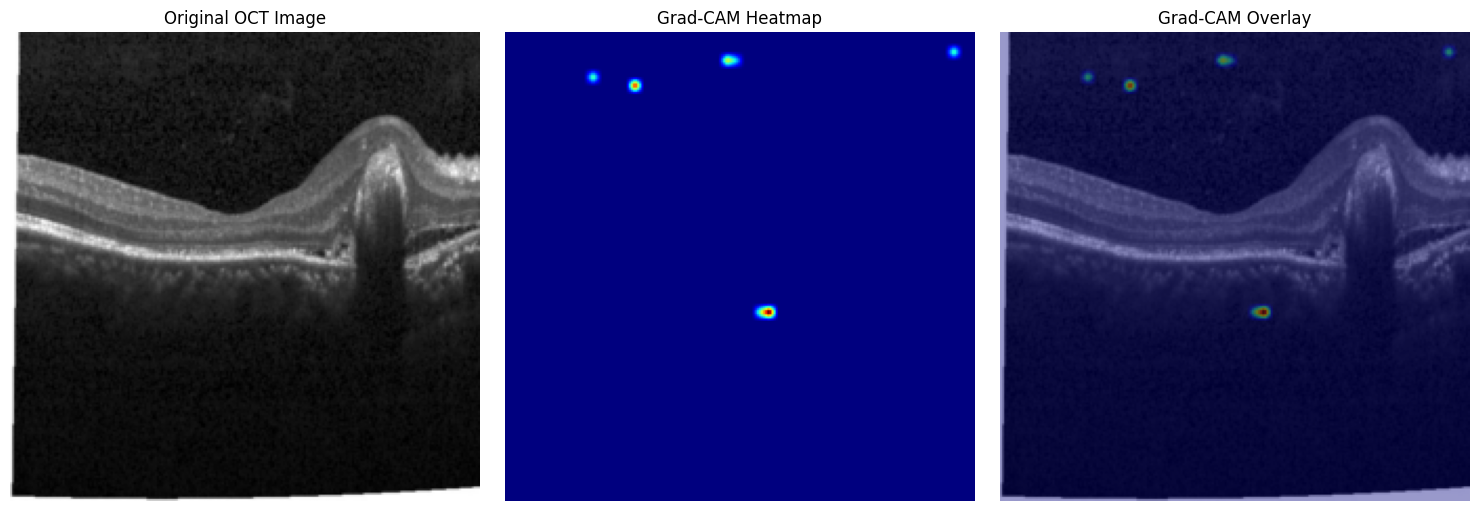

In [ ]:
original_image = image.squeeze().detach().cpu().numpy()

# Convert normalized image back to [0, 1]
original_image = (original_image + 1) / 2

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(original_image, cmap="gray")
plt.title("Original OCT Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(cam, cmap="jet")
plt.title("Grad-CAM Heatmap")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(original_image, cmap="gray")
plt.imshow(cam, cmap="jet", alpha=0.4)
plt.title("Grad-CAM Overlay")
plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Remove previously registered hooks
forward_handle.remove()
backward_handle.remove()

# Use activation after ReLU
target_layer = custom_cnn.features[7]

forward_handle = target_layer.register_forward_hook(forward_hook)
backward_handle = target_layer.register_full_backward_hook(backward_hook)

print("Grad-CAM target layer updated successfully!")

Grad-CAM target layer updated successfully!


In [ ]:
# Clear previous gradients
custom_cnn.zero_grad()

# Forward pass
output = custom_cnn(image)

predicted_class = output.argmax(dim=1).item()

# Backward pass
score = output[0, predicted_class]
score.backward()

# Calculate Grad-CAM
weights = gradients.mean(dim=(2, 3), keepdim=True)

cam = (weights * activations).sum(dim=1, keepdim=True)
cam = F.relu(cam)

cam = F.interpolate(
    cam,
    size=(224, 224),
    mode="bilinear",
    align_corners=False
)

cam = cam.squeeze().detach().cpu().numpy()

# Normalize
cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

print("Actual class:", actual_label)
print("Predicted class:", predicted_class)
print("Updated Grad-CAM generated!")

Actual class: 0
Predicted class: 0
Updated Grad-CAM generated!


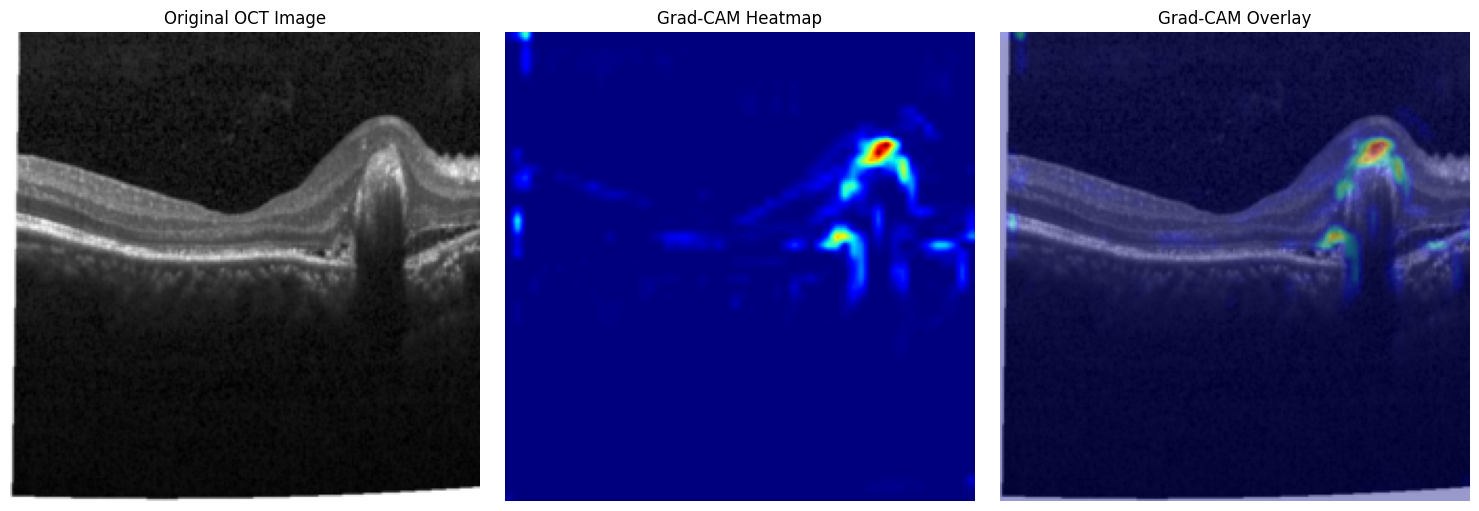

In [ ]:
original_image = image.squeeze().detach().cpu().numpy()

# Convert normalized image back to [0, 1]
original_image = (original_image + 1) / 2

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(original_image, cmap="gray")
plt.title("Original OCT Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(cam, cmap="jet")
plt.title("Grad-CAM Heatmap")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(original_image, cmap="gray")
plt.imshow(cam, cmap="jet", alpha=0.4)
plt.title("Grad-CAM Overlay")
plt.axis("off")

plt.tight_layout()
plt.show()

Grad-CAM was implemented on the Custom CNN using its final convolutional feature extraction stage. The heatmap highlighted regions around the retinal structure that contributed to the CNV prediction. The visualization provides insight into the model's decision-making process. However, some highlighted regions may not correspond directly to clinically meaningful abnormalities, indicating limitations in model interpretability.